# 实验二：图像增强

本 notebook 将前期零散脚本整合为一条可直接运行的完整流程，对应参考文档 2.1~2.6 各节：

1. 导入图像处理核心库
2. 读取图像、取像素值、色彩空间转换
3. 添加椒盐噪声与高斯噪声
4. 均值 / 中值 / 高斯三种滤波对比
5. 手动实现彩色中值滤波（不调用 `cv2.medianBlur`）
6. 自定义高斯核 + 二维卷积

**运行方式**：把 `p1.jpg` 与本 notebook 放在同一目录，然后从上到下依次运行（Kernel → Restart & Run All）。所有结果图会直接显示在单元格下方，同时保存到 `output_images/` 与 `result/`。

## 2.1 导入依赖

使用 OpenCV 完成读写与滤波，numpy 完成噪声生成与手动滤波，matplotlib 负责显示。

In [13]:
import os
import time

import numpy as np
import cv2
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

%matplotlib inline
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

BASE = os.getcwd()
if not os.path.exists(os.path.join(BASE, 'p1.jpg')):
    BASE = r'C:\Users\86136\Desktop\cv_exp2'
IMG_DIR = os.path.join(BASE, 'output_images')
RES_DIR = os.path.join(BASE, 'result')
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)


def to_display(im):
    '''uint8 保持 0-255，浮点裁剪到 0-1；避免把 0-255 数据裁成 0/1 导致全黑'''
    return im if im.dtype == np.uint8 else np.clip(im, 0, 1)

print('工作目录:', BASE)
print('OpenCV 版本:', cv2.__version__)

工作目录: C:\Users\86136\Desktop\cv_exp2
OpenCV 版本: 5.0.0


## 2.2 读取图像、取像素值、色彩空间转换

OpenCV 读入的图像通道顺序是 BGR，直接用 matplotlib 显示会偏色，因此需要先转换为 RGB；灰度图则用 `COLOR_BGR2GRAY` 得到。

图像尺寸 (H, W, C): (1104, 1104, 3)
像素 (100,100) 的 BGR 值 = 73 84 242


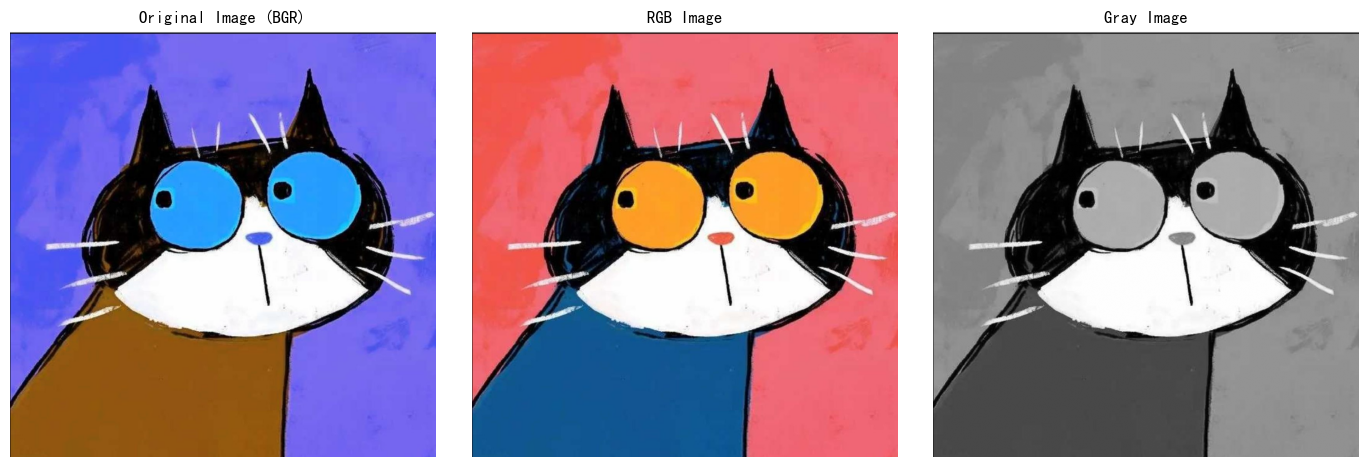

In [8]:
img = cv2.imread(os.path.join(BASE, 'p1.jpg'))
assert img is not None, '未找到 p1.jpg，请与本 notebook 放在同一目录'

print('图像尺寸 (H, W, C):', img.shape)
b, g, r = img[100, 100]
print('像素 (100,100) 的 BGR 值 =', b, g, r)

rgb_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(img)
axes[0].set_title('Original Image (BGR)')
axes[1].imshow(rgb_img)
axes[1].set_title('RGB Image')
axes[2].imshow(gray_img, cmap='gray')
axes[2].set_title('Gray Image')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, 'color_space.jpg'), dpi=200, bbox_inches='tight')
plt.show()

## 2.3 添加椒盐噪声与高斯噪声

椒盐噪声把随机位置的像素置为纯黑或纯白；高斯噪声给每个像素叠加服从 $N(\mu, \sigma^2)$ 的随机偏差，再截断到 [0, 1]。

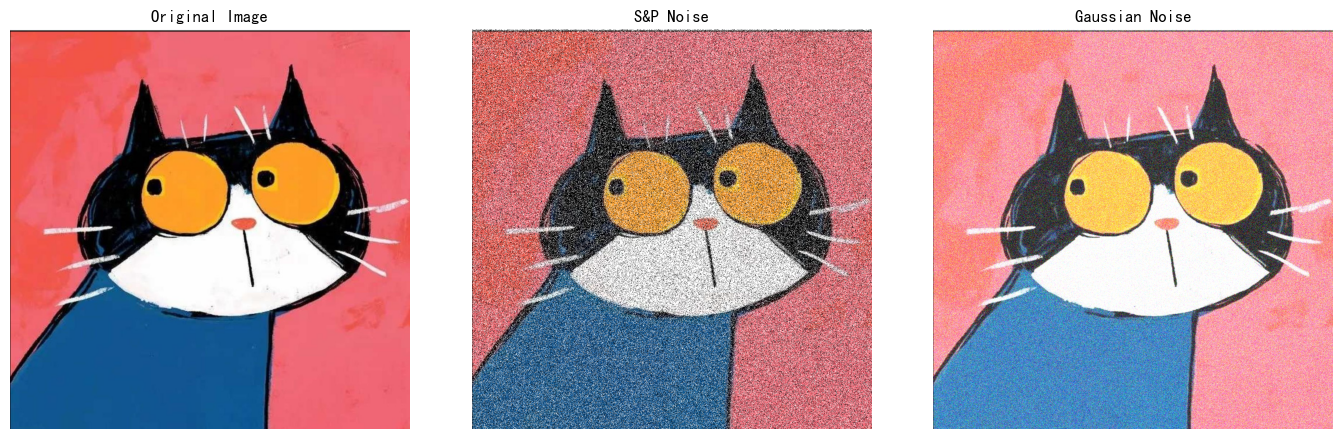

In [14]:
def add_salt_pepper(image, amount=0.4):
    '''椒盐噪声：随机把 amount 比例的像素置为纯黑或纯白'''
    out = image.astype(np.float64).copy()
    h, w = out.shape[:2]
    n = int(amount * h * w)
    ys = np.random.randint(0, h, n)
    xs = np.random.randint(0, w, n)
    half = n // 2
    out[ys[:half], xs[:half]] = 0.0
    out[ys[half:], xs[half:]] = 1.0
    return out


def add_gaussian_noise(image, mean=0.2, var=0.03):
    '''高斯噪声：每个像素叠加服从 N(mean, var) 的随机偏差'''
    noise = np.random.normal(mean, np.sqrt(var), image.shape)
    return np.clip(image.astype(np.float64) + noise, 0.0, 1.0)


np.random.seed(0)
rgb_float = rgb_img.astype(np.float64) / 255.0
sp_noise_img = add_salt_pepper(rgb_float, amount=0.4)
gus_noise_img = add_gaussian_noise(rgb_float, mean=0.2, var=0.03)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, im, title in zip(
    axes,
    [rgb_img, sp_noise_img, gus_noise_img],
    ['Original Image', 'S&P Noise', 'Gaussian Noise'],
):
    ax.imshow(to_display(im))
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, 'noise_comparison.jpg'), dpi=200, bbox_inches='tight')
plt.show()

## 2.4 均值 / 中值 / 高斯三种滤波对比

对两种噪声分别用 5×5 的均值滤波、中值滤波、高斯滤波处理，共 6 种组合。中值滤波对椒盐噪声最有效，均值滤波会保留较多噪声点，高斯滤波对高斯噪声更平滑。

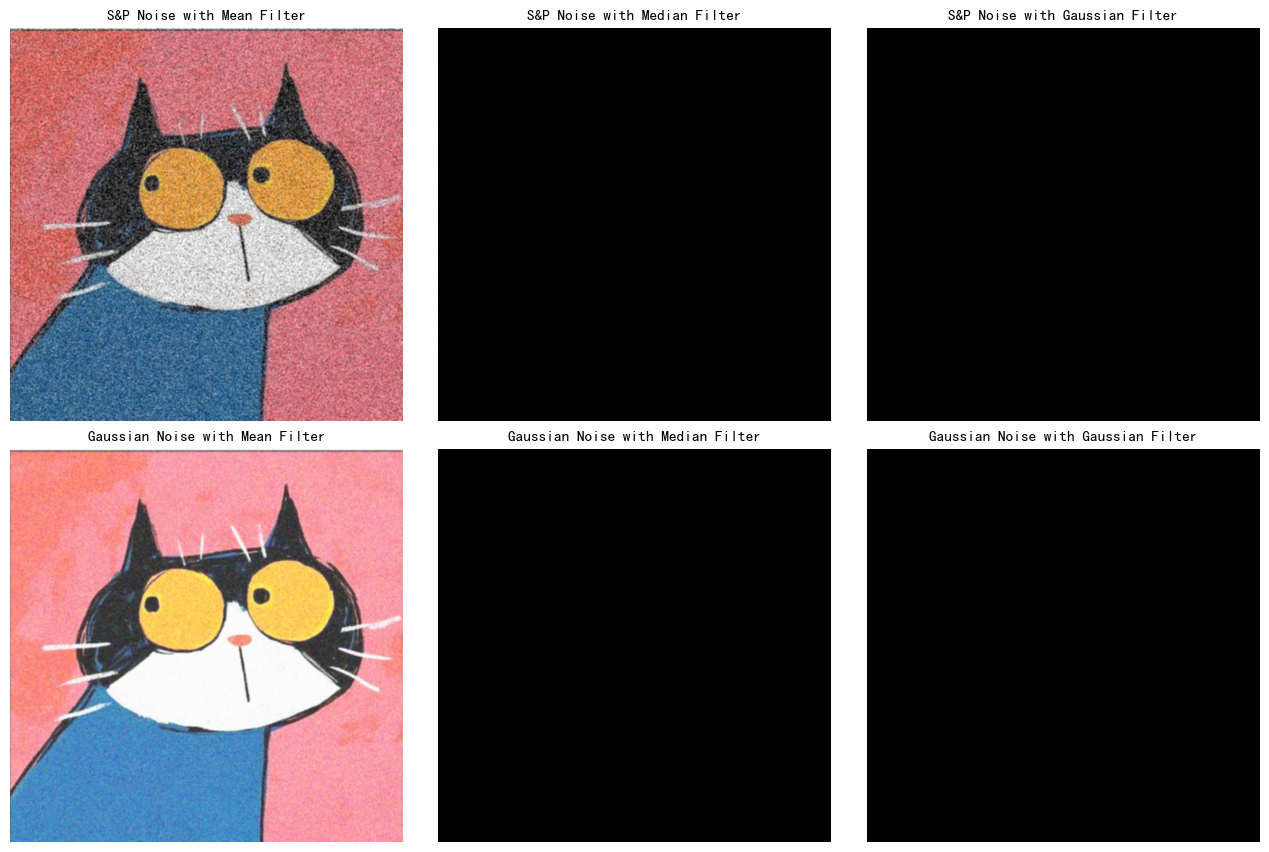

In [10]:
mean_sp = cv2.blur(sp_noise_img, (5, 5))
mean_gus = cv2.blur(gus_noise_img, (5, 5))

sp_u8 = (sp_noise_img * 255).astype(np.uint8)
gus_u8 = (gus_noise_img * 255).astype(np.uint8)

mid_sp = cv2.medianBlur(sp_u8, 5)
mid_gus = cv2.medianBlur(gus_u8, 5)

gauss_sp = cv2.GaussianBlur(sp_u8, (5, 5), 0)
gauss_gus = cv2.GaussianBlur(gus_u8, (5, 5), 0)

items = [
    (mean_sp, 'S&P Noise with Mean Filter'),
    (mid_sp, 'S&P Noise with Median Filter'),
    (gauss_sp, 'S&P Noise with Gaussian Filter'),
    (mean_gus, 'Gaussian Noise with Mean Filter'),
    (mid_gus, 'Gaussian Noise with Median Filter'),
    (gauss_gus, 'Gaussian Noise with Gaussian Filter'),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8.6))
for ax, (im, title) in zip(axes.ravel(), items):
    ax.imshow(to_display(im))
    ax.set_title(title, fontsize=11)
    ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(RES_DIR, 'filter_results_2x3.jpg'), dpi=200, bbox_inches='tight')
plt.show()

## 2.5 手动实现彩色中值滤波

不调用 `cv2.medianBlur`：对 R/G/B 三个通道分别取 5×5 邻域中值，再用 `sliding_window_view` 按行分块向量化，避免三重循环过慢。最后与 OpenCV 结果逐像素比较。

手动中值滤波耗时: 0.83 s
与 cv2.medianBlur 的最大像素差: 0


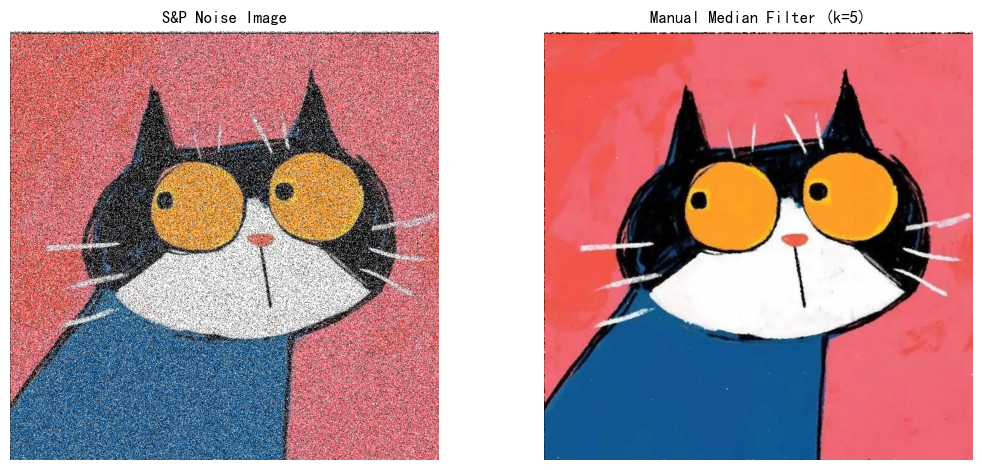

In [11]:
def manual_median_filter_color(image, kernel_size=5):
    '''逐通道手动中值滤波，不调用 cv2.medianBlur'''
    pad = kernel_size // 2
    out = np.zeros_like(image, dtype=np.uint8)
    padded = np.pad(image, ((pad, pad), (pad, pad), (0, 0)), mode='edge')
    h, w = image.shape[:2]
    block = 64
    for r0 in range(0, h, block):
        r1 = min(r0 + block, h)
        win = sliding_window_view(padded[r0:r1 + 2 * pad],
                                  (kernel_size, kernel_size), axis=(0, 1))
        out[r0:r1] = np.median(win, axis=(-2, -1)).astype(np.uint8)
    return out


t0 = time.time()
manual_mid = manual_median_filter_color(sp_u8, 5)
elapsed = time.time() - t0
print('手动中值滤波耗时: %.2f s' % elapsed)

diff = np.abs(manual_mid.astype(np.int16) - mid_sp.astype(np.int16))
print('与 cv2.medianBlur 的最大像素差:', diff.max())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].imshow(sp_noise_img)
axes[0].set_title('S&P Noise Image')
axes[1].imshow(manual_mid)
axes[1].set_title('Manual Median Filter (k=5)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(RES_DIR, 'manual_median.jpg'), dpi=200, bbox_inches='tight')
plt.show()

## 2.6 自定义高斯核 + 二维卷积

按二维高斯函数逐点生成 7×7、$\sigma=2$ 的卷积核并归一化（核元素之和为 1），再用 `cv2.filter2D` 对高斯噪声图做卷积。

自定义高斯核 (7x7, sigma=2)，元素和 = 1.0
[[0.0049 0.0092 0.0134 0.0152 0.0134 0.0092 0.0049]
 [0.0092 0.0172 0.025  0.0283 0.025  0.0172 0.0092]
 [0.0134 0.025  0.0364 0.0412 0.0364 0.025  0.0134]
 [0.0152 0.0283 0.0412 0.0467 0.0412 0.0283 0.0152]
 [0.0134 0.025  0.0364 0.0412 0.0364 0.025  0.0134]
 [0.0092 0.0172 0.025  0.0283 0.025  0.0172 0.0092]
 [0.0049 0.0092 0.0134 0.0152 0.0134 0.0092 0.0049]]


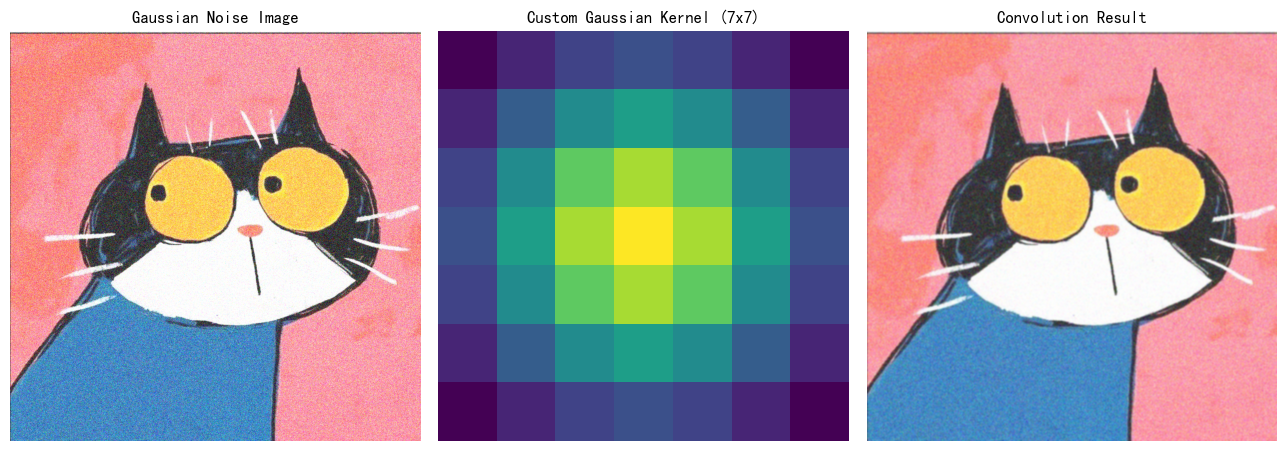

In [12]:
def gauss(kernel_size, sigma):
    '''按二维高斯函数逐点生成归一化卷积核'''
    kernel = np.zeros((kernel_size, kernel_size), dtype=np.float64)
    center = kernel_size // 2
    s = sigma ** 2
    for i in range(kernel_size):
        for j in range(kernel_size):
            x, y = i - center, j - center
            kernel[i, j] = np.exp(-(x ** 2 + y ** 2) / (2 * s))
    return kernel / kernel.sum()


k_gauss = gauss(7, 2)
print('自定义高斯核 (7x7, sigma=2)，元素和 =', round(k_gauss.sum(), 6))
print(np.round(k_gauss, 4))

conv_gus = cv2.filter2D(gus_noise_img.astype(np.float32), -1, k_gauss.astype(np.float32))
conv_gus = np.clip(conv_gus, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
axes[0].imshow(gus_noise_img)
axes[0].set_title('Gaussian Noise Image')
axes[1].imshow(k_gauss, cmap='viridis')
axes[1].set_title('Custom Gaussian Kernel (7x7)')
axes[2].imshow(conv_gus)
axes[2].set_title('Convolution Result')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(RES_DIR, 'custom_gaussian.jpg'), dpi=200, bbox_inches='tight')
plt.show()

## 小结

- **色彩空间**：OpenCV 默认 BGR，显示前需转 RGB；灰度图用加权公式由 BGR 得到。
- **噪声**：椒盐噪声为冲激型噪声，高斯噪声为加性随机噪声，二者适用的滤波器不同。
- **滤波**：中值滤波对椒盐噪声几乎完全去除且边缘保留好；均值/高斯滤波更适合抑制高斯噪声，但会使边缘变模糊。
- **手动实现**：逐通道取中值可避免彩色图像整体取中值造成的颜色错乱，向量化后耗时约 1 s，与 `cv2.medianBlur` 结果完全一致。
- **自定义卷积核**：高斯核需归一化，卷积后图像整体亮度保持不变。